In [1]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
house = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing.csv')

house.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             20000 non-null  int64  
 1   date           20000 non-null  object 
 2   bedrooms       20000 non-null  int64  
 3   bathrooms      20000 non-null  float64
 4   sqft_living    20000 non-null  int64  
 5   sqft_lot       20000 non-null  int64  
 6   floors         20000 non-null  float64
 7   waterfront     20000 non-null  int64  
 8   view           20000 non-null  int64  
 9   condition      20000 non-null  int64  
 10  grade          20000 non-null  int64  
 11  sqft_above     20000 non-null  int64  
 12  sqft_basement  20000 non-null  int64  
 13  yr_built       20000 non-null  int64  
 14  yr_renovated   20000 non-null  int64  
 15  zipcode        20000 non-null  int64  
 16  lat            20000 non-null  float64
 17  long           20000 non-null  float64
 18  sqft_l

In [2]:
import numpy as np

house['date'] = pd.to_datetime(house['date'])
house['sale_year'] = house['date'].dt.year
house['sale_month'] = house['date'].dt.month
house['age_at_sale'] = house['sale_year'] - house['yr_built']

last_work = np.maximum(house['yr_built'], house['yr_renovated'])
house['yrs_since_reno'] = house['sale_year'] - last_work
house['was_renovated'] = (house['yr_renovated'] > 0).astype(int)

house['has_basement'] = (house['sqft_basement'] > 0).astype(int)
house['basement_ratio'] = house['sqft_basement'] / house['sqft_living']

house['sqft_per_bedroom'] = house['sqft_living'] / house['bedrooms'].replace(0, 1)
house['bath_per_bed'] = house['bathrooms'] / house['bedrooms'].replace(0, 1)

def haversine(lat1, lon1, lat2, lon2):
    R = 3959
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

house['dist_to_seattle'] = haversine(house['lat'], house['long'], 47.6062, -122.3321)
house['dist_to_bellevue'] = haversine(house['lat'], house['long'], 47.6101, -122.2015)

In [3]:
y = house['price']
X = pd.get_dummies(house.drop(columns = ['price', 'id', 'date']), columns=['zipcode'])

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=10)

In [5]:
model = XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth = 6)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=800,
             n_jobs=None, num_parallel_tree=None, ...)

In [6]:
from sklearn.metrics import r2_score

predictions = model.predict(X_test)

rmse_result = root_mean_squared_error(y_test, predictions)
r2_result = r2_score(y_test, predictions)

print(f"RMSE: {round(rmse_result, 2)}")
print(f"R2 Score: {round(r2_result, 4)}")

RMSE: 101498.41
R2 Score: 0.9223


In [7]:
# 1. Load the holdout houses
holdout = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing_holdout_test_mini.csv')

# 2. Apply the SAME feature engineering you did to training data
holdout['date'] = pd.to_datetime(holdout['date'])
holdout['sale_year'] = holdout['date'].dt.year
holdout['sale_month'] = holdout['date'].dt.month
holdout['age_at_sale'] = holdout['sale_year'] - holdout['yr_built']

last_work = np.maximum(holdout['yr_built'], holdout['yr_renovated'])
holdout['yrs_since_reno'] = holdout['sale_year'] - last_work
holdout['was_renovated'] = (holdout['yr_renovated'] > 0).astype(int)

holdout['has_basement'] = (holdout['sqft_basement'] > 0).astype(int)
holdout['basement_ratio'] = holdout['sqft_basement'] / holdout['sqft_living']

holdout['sqft_per_bedroom'] = holdout['sqft_living'] / holdout['bedrooms'].replace(0, 1)
holdout['bath_per_bed'] = holdout['bathrooms'] / holdout['bedrooms'].replace(0, 1)

def haversine(lat1, lon1, lat2, lon2):
    R = 3959  # miles; use 6371 for km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

holdout['dist_to_seattle'] = haversine(holdout['lat'], holdout['long'], 47.6062, -122.3321)
holdout['dist_to_bellevue'] = haversine(holdout['lat'], holdout['long'], 47.6101, -122.2015)



# 3. Apply the SAME drops + one-hot encoding
holdout_X = pd.get_dummies(holdout.drop(columns=['id', 'date']), columns=['zipcode'])

# 4. Align columns to match training X exactly (the critical safety net)
holdout_X = holdout_X.reindex(columns=X.columns, fill_value=0)

# 5. Predict
holdout_predictions = model.predict(holdout_X)

# 6. Write the CSV — exactly one column, header 'price', no index
output = pd.DataFrame({'price': holdout_predictions})
output.to_csv('BCF-module3-predictions.csv', index=False)

BREAK

In [8]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
print(f"Train RMSE: ${root_mean_squared_error(y_train, train_predictions):,.2f}")
print(f"Test RMSE:  ${root_mean_squared_error(y_test, test_predictions):,.2f}")

Train RMSE: $46,214.86
Test RMSE:  $101,498.41


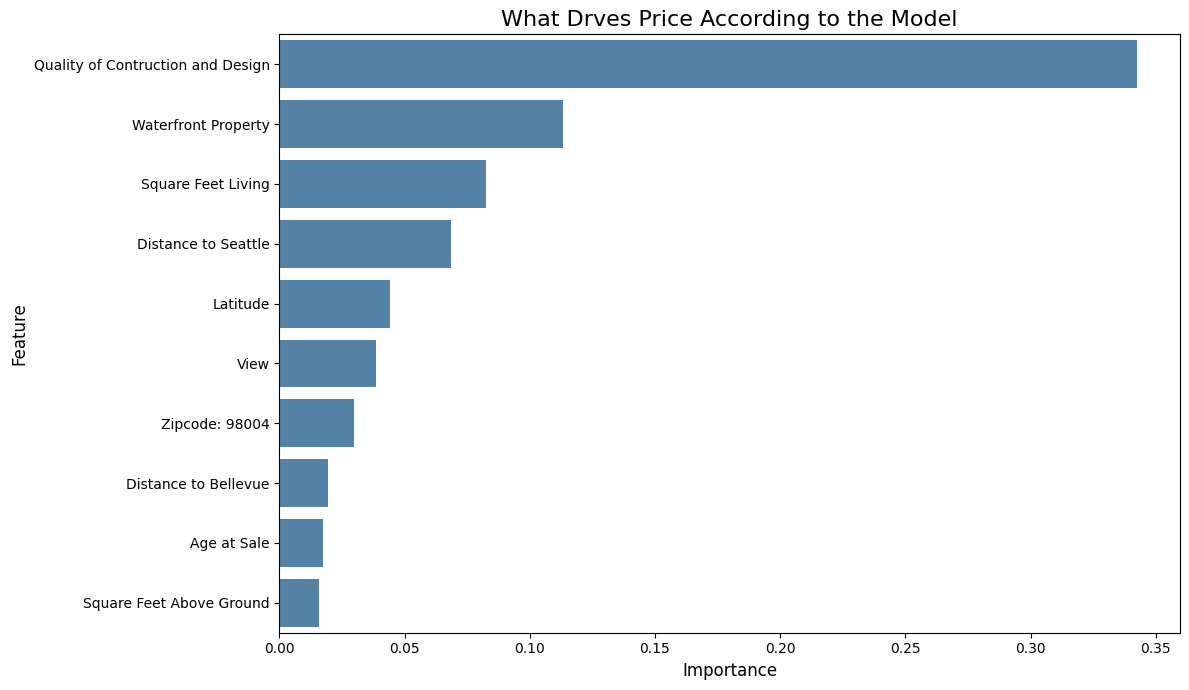

In [9]:
from xgboost import XGBRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

importances = model.feature_importances_
feature_importance_df = pd.DataFrame({'feature': X.columns, 'importance': importances})

# Sort by importance and get the top 10
top_10_features = feature_importance_df.sort_values(by='importance', ascending=False).head(10)

# Rename features for better readability
feature_names_mapping = {
    'dist_to_seattle': 'Distance to Seattle',
    'lat': 'Latitude',
    'zipcode_98004': 'Zipcode: 98004',
    'dist_to_bellevue': 'Distance to Bellevue',
    'sqft_above': 'Square Feet Above Ground',
    'sqft_living': 'Square Feet Living',
    'waterfront': 'Waterfront Property',
    'age_at_sale': 'Age at Sale',
    'grade': 'Quality of Contruction and Design',
    'view': 'View'
}

top_10_features['feature'] = top_10_features['feature'].replace(feature_names_mapping)

# Create the bar chart with a blue color scheme and improved readability
plt.figure(figsize=(12, 7))
sns.barplot(x='importance', y='feature', data=top_10_features, color ='steelblue', legend=False)
plt.title('What Drves Price According to the Model', fontsize=16)
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

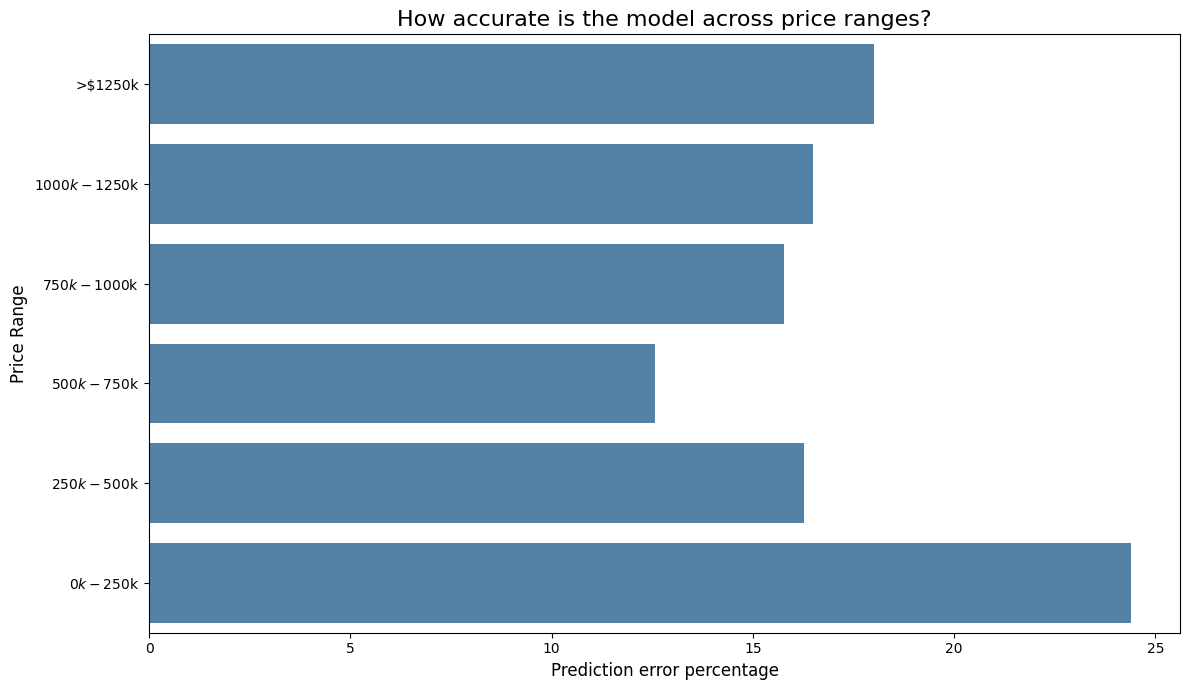

In [10]:
results = pd.DataFrame({'actual': y_test, 'predicted': predictions})

# Define 6 price bins: 5 bins of $250k, and one 'over $1.25M' bin
bins = [0, 250000, 500000, 750000, 1000000, 1250000, results['actual'].max() + 1]
labels = ['$0k - $250k', '$250k - $500k', '$500k - $750k', '$750k - $1000k', '$1000k - $1250k', '>$1250k']

results['price_bin'] = pd.cut(results['actual'], bins=bins, labels=labels, right=False)

# Calculate RMSE for each bin, handling empty bins
rmse_per_bin_data = []
for name, group in results.groupby('price_bin', observed=False):
    if not group.empty:
        rmse = root_mean_squared_error(group['actual'], group['predicted'])
        mean_actual_price = group['actual'].mean()
        rmse_percentage = (rmse / mean_actual_price) * 100 if mean_actual_price != 0 else np.nan
        rmse_per_bin_data.append({'price_bin': name, 'RMSE_Percentage': rmse_percentage})

rmse_per_bin_df = pd.DataFrame(rmse_per_bin_data).dropna()

# Plotting the RMSE per price bin
plt.figure(figsize=(12, 7))
sns.barplot(x='RMSE_Percentage', y='price_bin', data=rmse_per_bin_df, color='steelblue')
plt.title('How accurate is the model across price ranges?', fontsize=16)
plt.xlabel('Prediction error percentage', fontsize=12)
plt.ylabel('Price Range', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.gca().invert_yaxis() # Invert y-axis to have lower prices at the top
plt.tight_layout()
plt.show()